In [40]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [41]:
train_path = "../data/raw/train.csv"
test_path = "../data/raw/test.csv"

train_raw = pd.read_csv(train_path)
test = pd.read_csv(test_path)
train = train_raw.copy()

# EDA

## Базовые статистики и распределения

In [42]:
train.describe(include = 'all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


### Распределение возраста пассажиров

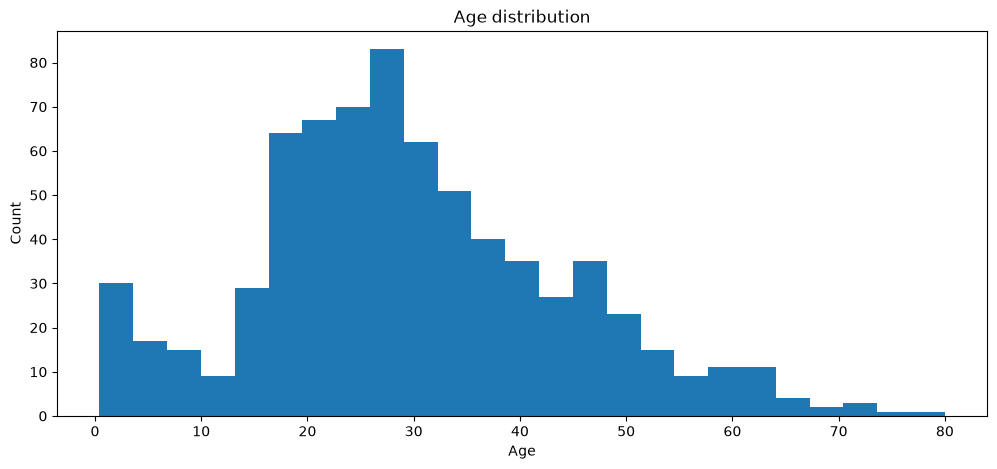

In [43]:
plt.figure(figsize=(12, 5))

plt.hist(train['Age'].dropna(), bins=25)

plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age distribution')

plt.show()

### Распределение пола пассажиров

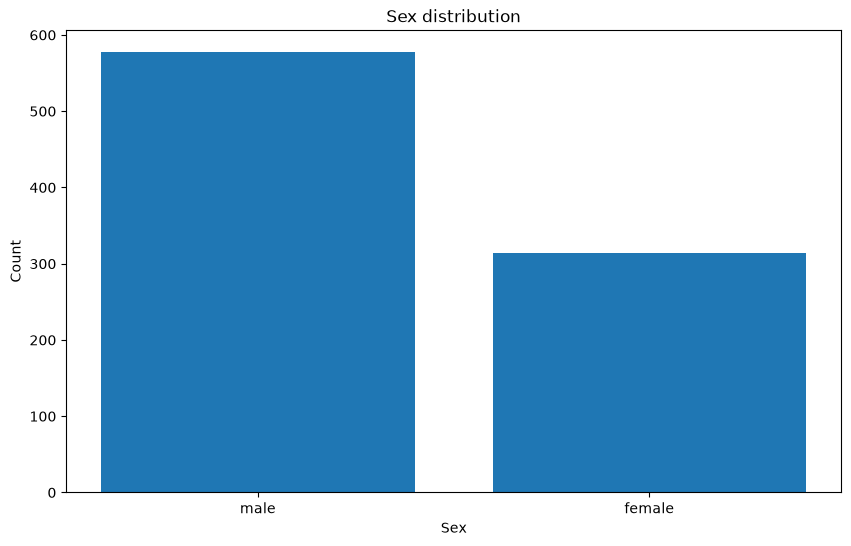

In [44]:
sex_counts = train['Sex'].value_counts()
plt.figure(figsize=(10, 6))
plt.bar(sex_counts.index, sex_counts.values)

plt.xlabel('Sex')
plt.ylabel('Count')
plt.title('Sex distribution')

plt.show()

### Распределение шанса на выживание на основе класса пассажиров

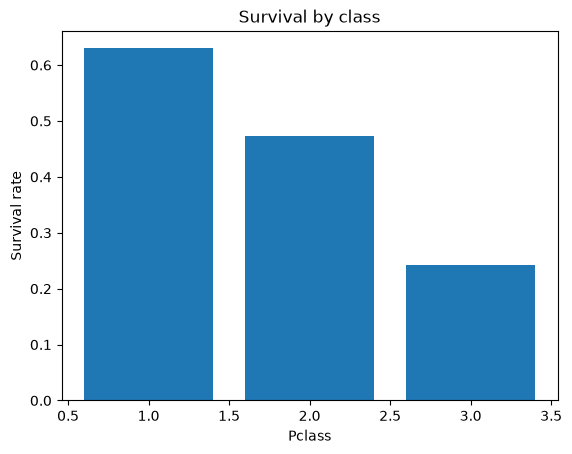

In [45]:
survival_by_class = train.groupby('Pclass')['Survived'].mean()

plt.bar(survival_by_class.index, survival_by_class.values)

plt.xlabel('Pclass')
plt.ylabel('Survival rate')
plt.title('Survival by class')

plt.show()

### Распределение шанса на выживание на основе возраста пассажиров (взяты промежутки по 10 лет)

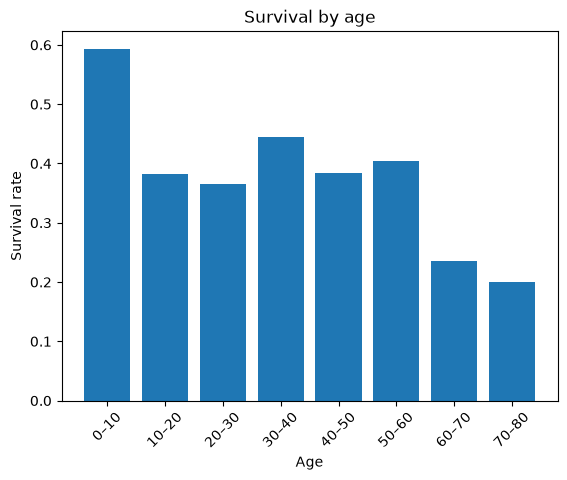

In [46]:
age_bin = pd.cut(train['Age'], bins=range(0, 91, 10))
survival_by_age = train.groupby(age_bin, observed=True)['Survived'].mean()

x_label = [f'{x.left}–{x.right}' for x in survival_by_age.index]

plt.bar(x_label, survival_by_age.values)
plt.xticks(rotation=45)
plt.xlabel('Age')
plt.ylabel('Survival rate')
plt.title('Survival by age')

plt.show()

## Исследование данных

In [47]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### Проверка на наличие константных фичей в данных

In [48]:
constant_features = train.columns[train.nunique() == 1]

constant_features

Index([], dtype='object')

### Проверка пропусков в данных

In [49]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Обработка пропущенных значений "Age"

##### Исследование людей с пропуском Age

In [50]:
train.groupby('Sex')['Age'].apply( lambda x: sum(x.isna()) / len(x) )

Sex
female    0.168790
male      0.214905
Name: Age, dtype: float64

In [51]:
train.groupby('Survived')['Age'].apply(lambda x: sum(x.isna()) / len(x))

Survived
0    0.227687
1    0.152047
Name: Age, dtype: float64

In [52]:
train.groupby(train['Age'].isna())['Survived'].mean()

Age
False    0.406162
True     0.293785
Name: Survived, dtype: float64

In [53]:
train.groupby([train['Age'].isna(), 'Pclass'])['Survived'].mean()

Age    Pclass
False  1         0.655914
       2         0.479769
       3         0.239437
True   1         0.466667
       2         0.363636
       3         0.250000
Name: Survived, dtype: float64

##### Возможно отсутствие возраста имеет корреляцию с таргетом, поэтому оставляем фичу Age_missing, возможно это поможет в обучении

In [54]:
train['Age_missing'] = train['Age'].isna()
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_missing
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False


##### Извлекаем из колонки Name title человека (Mr, Miss и тд), по которому можно понять возраст представленного человека (взять median по группе людей с таким же title)

In [55]:
train['Name'].head()

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
Name: Name, dtype: object

In [56]:
def get_title(name):
    match = re.search(r',\s*([^\.]+)\.', name)
    return match.group(1) if match else 'Other'

train['Title'] = train['Name'].apply(get_title)
test['Title'] = test['Name'].apply(get_title)

#train.groupby('Title')['Survived'].mean()
train['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [57]:
main_titles = ['Mr', 'Miss', 'Mrs', 'Master']

train['Title'] = train['Title'].where(
    train['Title'].isin(main_titles),
    'Other'
)
test['Title'] = test['Title'].where(
    test['Title'].isin(main_titles),
    'Other'
)

In [58]:
train['Title'].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Other      27
Name: count, dtype: int64

In [59]:
train['Age'] = train['Age'].fillna(
    train.groupby('Title')['Age'].transform('median')
)

### Обработка пропущенных значений "Cabin"

In [60]:
train.groupby(train['Cabin'].isna())['Survived'].mean()

Cabin
False    0.666667
True     0.299854
Name: Survived, dtype: float64

##### Видим, что отсутствие Cabin связано с 2х уменьшением таргета - возможно следует учитывать Cabin_missing = 'Unknown'

In [61]:
train.groupby([train['Cabin'].isna(), 'Pclass'])['Survived'].mean()

Cabin  Pclass
False  1         0.664773
       2         0.812500
       3         0.500000
True   1         0.475000
       2         0.440476
       3         0.235908
Name: Survived, dtype: float64

In [62]:
train['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'B28', 'C83', 'F33',
       'F G73', 'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101',
       'F E69', 'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54',
       'B57 B59 B63 B66', 'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40',
       'T', 'C128', 'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44',
       'A34', 'C104', 'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14',
       'B37', 'C30', 'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38',
       'B39', 'B22', 'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68',
       'B41', 'A20', 'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48',
       'E58', 'C126', 'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63',
       'C62 C64',

In [63]:
train['Cabin'].dropna().str.findall(r'[A-Z]').explode().unique()

array(['C', 'E', 'G', 'D', 'A', 'B', 'F', 'T'], dtype=object)

In [64]:
sectors = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']
def get_sector(cabin):
    if pd.isna(cabin):
        return 'Unknown'
    match = re.search(r'[A-Z]', cabin)
    return match.group(0)

train['Deck'] = train['Cabin'].apply(get_sector)

In [65]:
train.groupby(['Deck', 'Pclass'])['Survived'].mean()

Deck     Pclass
A        1         0.466667
B        1         0.744681
C        1         0.593220
D        1         0.758621
         2         0.750000
E        1         0.720000
         2         0.750000
         3         1.000000
F        2         0.875000
         3         0.200000
G        3         0.500000
T        1         0.000000
Unknown  1         0.475000
         2         0.440476
         3         0.235908
Name: Survived, dtype: float64

### Обработка пропущенных значений "Embarked"

In [66]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_missing,Title,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,Mr,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,Mrs,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False,Miss,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,Mrs,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,Mr,Unknown


In [67]:
train.groupby(['Embarked'])['PassengerId'].count()

Embarked
C    168
Q     77
S    644
Name: PassengerId, dtype: int64

In [68]:
train.loc[ train['Embarked'].isna() == True, 'Embarked'] = 'S'
train[train['Embarked'].isna() == True ]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_missing,Title,Deck


##### Заменили все NaN в 'Embarked' на моду 'S'

### Проверка корреляции фичей

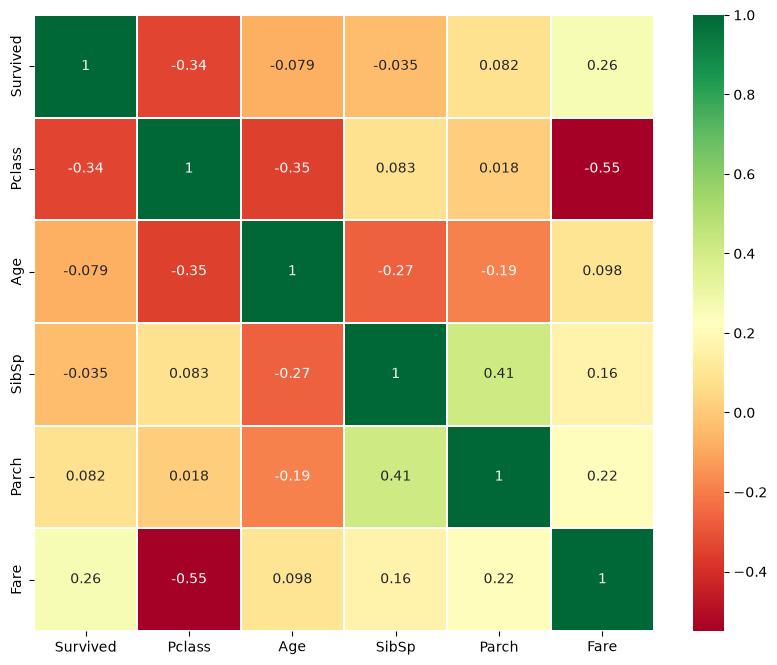

In [69]:
sns.heatmap(train[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr(),annot=True,cmap='RdYlGn',linewidths=0.2)
fig=plt.gcf()
fig.set_size_inches(10,8)
plt.show()

### Анализ выбросов

#### Проверка выбросов Age

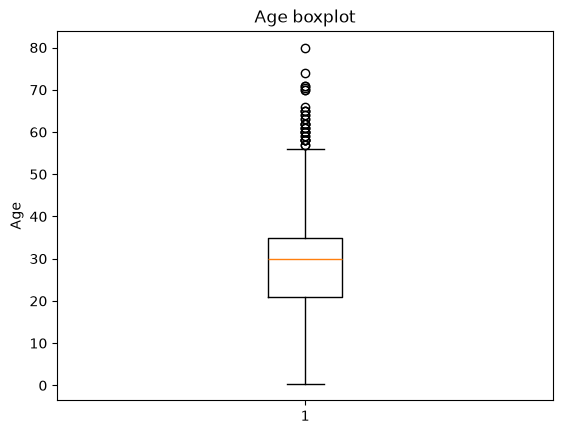

In [70]:
plt.boxplot(train['Age'].dropna())
plt.ylabel('Age')
plt.title('Age boxplot')
plt.show()

In [71]:
Q1 = train['Age'].quantile(0.25)
Q3 = train['Age'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
train[ train['Age'] > upper ].shape[0]

35

#### Проверка выбросов Fare

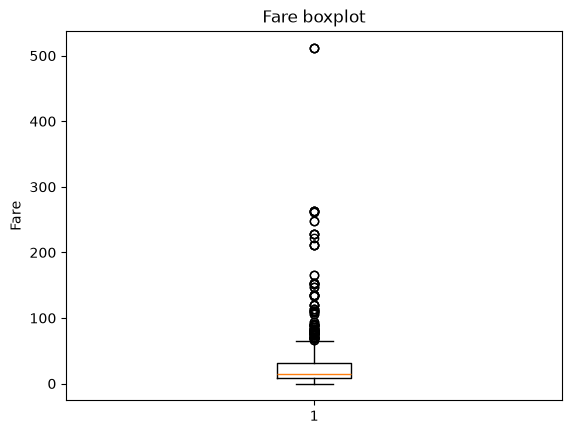

In [72]:
plt.boxplot(train['Fare'].dropna())
plt.ylabel('Fare')
plt.title('Fare boxplot')
plt.show()

In [73]:
Q1 = train['Fare'].quantile(0.25)
Q3 = train['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
train[ train['Fare'] > upper ].shape[0]

116

In [74]:
train['ticket_size'] = train.groupby('Ticket')['Ticket'].transform('size')
train.groupby('ticket_size')['Survived'].mean()

ticket_size
1    0.297989
2    0.574468
3    0.698413
4    0.500000
5    0.000000
6    0.000000
7    0.238095
Name: Survived, dtype: float64

In [75]:
train.groupby(['ticket_size','Sex'])['Survived'].mean()

ticket_size  Sex   
1            female    0.746269
             male      0.152542
2            female    0.813725
             male      0.290698
3            female    0.944444
             male      0.370370
4            female    0.592593
             male      0.352941
5            female    0.000000
             male      0.000000
6            female    0.000000
             male      0.000000
7            female    0.000000
             male      0.384615
Name: Survived, dtype: float64

In [76]:
outliers = train[train['Fare'] > upper]

outliers['Pclass'].value_counts()

Pclass
1    104
3      7
2      5
Name: count, dtype: int64

In [77]:
outliers.groupby(['Pclass', 'ticket_size'])['Fare'].describe()

# Вероятно у людей с одинаковыми Ticket указан общий Fare на группу и имеет смысл разделить его на количество людей в группе

count        mean         std       min       25%  \
Pclass ticket_size                                                      
1      1              9.0  108.835644   61.275143   71.2833   76.2917   
       2             48.0  108.656250   51.209616   66.6000   79.1125   
       3             27.0  160.763889  133.780428   76.7292   79.6500   
       4             20.0  174.591660   61.879162  110.8833  120.0000   
2      5              5.0   73.500000    0.000000   73.5000   73.5000   
3      7              7.0   69.550000    0.000000   69.5500   69.5500   

                         50%       75%       max  
Pclass ticket_size                                
1      1             79.2000   83.1583  221.7792  
       2             89.5521  115.0875  262.3750  
       3            113.2750  153.4625  512.3292  
       4            151.5500  227.5250  263.0000  
2      5             73.5000   73.5000   73.5000  
3      7             69.5500   69.5500   69.5500

In [78]:
train.groupby('Ticket')['Fare'].nunique().sort_values(ascending=False).head(10)

Ticket
7534         2
111426       1
WE/P 5735    1
110152       1
110413       1
110465       1
110564       1
110813       1
111240       1
113056       1
Name: Fare, dtype: int64

In [79]:
train[ train['Ticket'] == '7534' ]
# Получили что это может быть просто ошибкой в данных, поэтому для данного тикета изменим Fare на среднее значение по классу, то есть на 9,53125

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_missing,Title,Deck,ticket_size
138,139,0,3,"Osen, Mr. Olaf Elon",male,16.0,0,0,7534,9.2167,NaN,S,False,Mr,Unknown,2
876,877,0,3,"Gustafsson, Mr. Alfred Ossian",male,20.0,0,0,7534,9.8458,NaN,S,False,Mr,Unknown,2


In [80]:
train.loc[train['Ticket'] == '7534', 'Fare'] = 9.53125

In [81]:
train.sort_values(by='Fare', ascending=False).head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_missing,Title,Deck,ticket_size
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C,False,Mr,B,3
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C,False,Miss,Unknown,3
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C,False,Mr,B,3
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S,False,Miss,C,4
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S,False,Mr,C,4
341,342,1,1,"Fortune, Miss. Alice Elizabeth",female,24.0,3,2,19950,263.0000,C23 C25 C27,S,False,Miss,C,4
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S,False,Mr,C,4
742,743,1,1,"Ryerson, Miss. Susan Parker ""Suzette""",female,21.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C,False,Miss,B,2
311,312,1,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C,False,Miss,B,2
299,300,1,1,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",female,50.0,0,1,PC 17558,247.5208,B58 B60,C,False,Mrs,B,2


In [82]:
# Заменяем все Fare на среднее значение по классу для тикетов, которые встречаются более одного раза

train['Fare_per_person'] = train['Fare'] / train['ticket_size']

In [83]:
Q1 = train['Fare_per_person'].quantile(0.25)
Q3 = train['Fare_per_person'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
train[ train['Fare_per_person'] > upper ].shape[0]

59

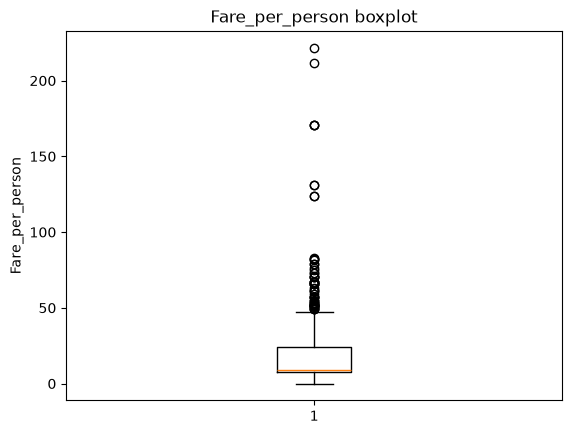

In [84]:
plt.boxplot(train['Fare_per_person'].dropna())
plt.ylabel('Fare_per_person')
plt.title('Fare_per_person boxplot')
plt.show()

In [ ]:
### В итоге в preprocessing это не было добавлено ввиду того, что нельзя будет адекватно оценивать ticket_size на валидации и тестовой выборке

### Обработка категориальных фичей

In [85]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_missing,Title,Deck,ticket_size,Fare_per_person
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,Mr,Unknown,1,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,Mrs,C,1,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False,Miss,Unknown,1,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,Mrs,C,2,26.5500
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,Mr,Unknown,1,8.0500


In [102]:
train1 = train.copy()
train1.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace=True)
train1.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Age_missing,Title,Deck,ticket_size,Fare_per_person
0,0,3,male,22.0,1,0,7.2500,S,False,Mr,Unknown,1,7.2500
1,1,1,female,38.0,1,0,71.2833,C,False,Mrs,C,1,71.2833
2,1,3,female,26.0,0,0,7.9250,S,False,Miss,Unknown,1,7.9250
3,1,1,female,35.0,1,0,53.1000,S,False,Mrs,C,2,26.5500
4,0,3,male,35.0,0,0,8.0500,S,False,Mr,Unknown,1,8.0500


In [104]:
train1['Sex'] = train1['Sex'].map({'male': 0, 'female': 1})
train1['Age_missing'] = train1['Age_missing'].map({False: 0, True: 1})
train1.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Age_missing,Title,Deck,ticket_size,Fare_per_person
0,0,3,0,22.0,1,0,7.2500,S,0,Mr,Unknown,1,7.2500
1,1,1,1,38.0,1,0,71.2833,C,0,Mrs,C,1,71.2833
2,1,3,1,26.0,0,0,7.9250,S,0,Miss,Unknown,1,7.9250
3,1,1,1,35.0,1,0,53.1000,S,0,Mrs,C,2,26.5500
4,0,3,0,35.0,0,0,8.0500,S,0,Mr,Unknown,1,8.0500


In [105]:
from sklearn.preprocessing import OneHotEncoder

cat_features = ['Embarked', 'Title', 'Deck']

# Создаём и обучаем encoder
encoder = OneHotEncoder(handle_unknown='ignore')
encoded = encoder.fit_transform(train1[cat_features])

# Получаем названия новых признаков
feature_names = encoder.get_feature_names_out(cat_features)

# Превращаем результат encoder в DataFrame
encoded_df = pd.DataFrame(
    encoded.toarray(),
    columns=feature_names,
    index=train1.index
)

# Удаляем исходные категориальные признаки
train1.drop(columns=cat_features, inplace=True)

# Добавляем One-Hot признаки
train1 = pd.concat([train1, encoded_df], axis=1)
train1.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Age_missing,ticket_size,Fare_per_person,...,Title_Other,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown
0,0,3,0,22.0,1,0,7.2500,0,1,7.2500,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1,1,1,38.0,1,0,71.2833,0,1,71.2833,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,3,1,26.0,0,0,7.9250,0,1,7.9250,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1,1,1,35.0,1,0,53.1000,0,2,26.5500,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,3,0,35.0,0,0,8.0500,0,1,8.0500,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
